# Phase 10 — Training the Primary Model

**Project:** Physics-Informed GAT for Diabetic Foot Plantar Thermography
**Notebook:** `09_training.ipynb`

## ⚠️ TEST SPLIT RULE — READ BEFORE RUNNING ANYTHING ⚠️

**`test_loader` / the test split is never touched anywhere in this notebook.**
Only `train_loader` (training) and `val_loader` (model selection, early
stopping, LR scheduling) are used. The test split is reserved exclusively
for Phase 11's single, final, one-time evaluation — using it here for
*anything*, even just to peek at a metric, would compromise its validity as
an unbiased final estimate.

This notebook trains **one** configuration — `PRIMARY_CONFIG` (dual-branch,
base graph topology, colormap image branch). Phase 12 will vary the
configuration for the ablation study; this phase just needs one trained,
checkpointed model to hand to Phase 11.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score
import json

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import build_dataloaders, load_normalization_stats
from src.model import DualBranchGAT

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Torch version:", torch.__version__)

Project root: c:\workstation\3RD YEAR\Diabetic_Foot
Torch version: 2.11.0+cu128


## Section 1 — Setup

Seed everything, detect device, build the real dataloaders, and compute
class weights **from the train split only** (recomputed fresh from
`patient_split.csv`, never hardcoded — the exact same discipline used in
every prior phase).

**Why DM's own weight is used as `pos_weight`, not Control's:** labels are
`1 = DM, 0 = Control`. DM is the *majority* class in train. `nn.BCEWithLogitsLoss`'s
`pos_weight` multiplies **only** the label=1 (DM) loss term — the label=0
(Control) term keeps a fixed coefficient of 1. Inverse-frequency weighting
gives the majority class (DM) a **smaller** weight (<1). Setting
`pos_weight` to that smaller DM weight correctly **downweights** DM's
already-plentiful loss contribution relative to Control's fixed
coefficient — that's what achieves balance. Using Control's (larger) weight
instead would do the opposite: further inflate the majority class's
influence. This is a common and easy mistake to make in the wrong direction.

In [2]:
print("=== SECTION 1: Setup ===")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

normalization_stats = load_normalization_stats(PROCESSED_DIR)
loaders = build_dataloaders(PROCESSED_DIR, normalization_stats, batch_size=16)
train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]  # noqa: F841 -- loaded for completeness only, NEVER iterated in this notebook

print(f"train: {len(loaders['train_dataset'])}  val: {len(loaders['val_dataset'])}  "
      f"test: {len(loaders['test_dataset'])} (test split loaded but will not be touched)")

# --- Class weights, recomputed fresh from patient_split.csv (train split only) ---
patient_split_df = pd.read_csv(PROCESSED_DIR / "patient_split.csv")
train_subjects_df = patient_split_df.loc[patient_split_df["split"] == "train"]

group_counts = train_subjects_df["Group"].value_counts()
n_train = len(train_subjects_df)
count_dm = int(group_counts.get("DM", 0))
count_control = int(group_counts.get("Control", 0))

weight_dm = n_train / (2 * count_dm)
weight_control = n_train / (2 * count_control)

print(f"\nTrain subjects: {n_train}  (DM={count_dm}, Control={count_control})")
print(f"Inverse-frequency weight_DM      = {weight_dm:.4f}")
print(f"Inverse-frequency weight_Control = {weight_control:.4f}")
print(f"\nUsing weight_DM ({weight_dm:.4f}) as pos_weight: DM is the majority class (label=1), "
      f"so its own (smaller) inverse-frequency weight downweights its loss contribution relative "
      f"to Control's fixed coefficient of 1 -- this is what balances the loss.")

PRIMARY_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": True,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3,
}
print("\nPRIMARY_CONFIG:", PRIMARY_CONFIG)

=== SECTION 1: Setup ===
Device: cuda
train: 232  val: 50  test: 52 (test split loaded but will not be touched)

Train subjects: 116  (DM=85, Control=31)
Inverse-frequency weight_DM      = 0.6824
Inverse-frequency weight_Control = 1.8710

Using weight_DM (0.6824) as pos_weight: DM is the majority class (label=1), so its own (smaller) inverse-frequency weight downweights its loss contribution relative to Control's fixed coefficient of 1 -- this is what balances the loss.

PRIMARY_CONFIG: {'use_graph_branch': True, 'use_image_branch': True, 'graph_topology': 'base', 'image_key': 'colormap_image', 'image_in_channels': 3}


## Section 2 — Model, Loss, Optimizer Builders

`build_model(config)` maps a `PRIMARY_CONFIG`-style dict to a `DualBranchGAT`
instance. Only `use_graph_branch`, `use_image_branch`, and
`image_in_channels` are constructor arguments — `graph_topology` and
`image_key` are `forward()`-time arguments, not constructor arguments, so
they're intentionally ignored here.

The loss criterion is built once, here, using the DM weight from Section 1.
**The optimizer and LR scheduler are deliberately built fresh inside
`train_model()` (Section 4), not here** — this keeps `train_model()`
self-contained so Phase 12's ablation notebook can call it repeatedly across
different configs without any shared, accidentally-stale optimizer state
leaking between runs.

In [3]:
def build_model(config: dict) -> DualBranchGAT:
    """Maps a config dict (PRIMARY_CONFIG-style) to a DualBranchGAT instance.
    Only the constructor-relevant keys are used; graph_topology/image_key are
    forward()-time arguments and are intentionally ignored here.
    """
    return DualBranchGAT(
        use_graph_branch=config["use_graph_branch"],
        use_image_branch=config["use_image_branch"],
        image_in_channels=config["image_in_channels"],
    )


criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm, dtype=torch.float32))

print("=== SECTION 2: Model / Loss builders defined ===")
print("criterion: BCEWithLogitsLoss(pos_weight=%.4f)" % weight_dm)
_smoke_model = build_model(PRIMARY_CONFIG)
print("build_model(PRIMARY_CONFIG) OK ->", type(_smoke_model).__name__)
del _smoke_model

=== SECTION 2: Model / Loss builders defined ===
criterion: BCEWithLogitsLoss(pos_weight=0.6824)
build_model(PRIMARY_CONFIG) OK -> DualBranchGAT


## Section 3 — Train / Eval Step Functions

`train_one_epoch()` is a standard training loop: zero grad, forward, loss,
backward, gradient clipping (`max_norm=5.0`, guards against any single bad
batch producing an exploding update), optimizer step.

`evaluate()` is **plain `model.eval()`** — no `enable_mc_dropout()` anywhere
in this notebook. MC-Dropout is reserved for Phase 11's final evaluation on
this trained model; mixing it in here would make every validation metric
noisy and non-reproducible, which would corrupt early stopping and model
selection. Predictions use `sigmoid(logits) >= 0.5` for the hard metrics
(accuracy, balanced accuracy, F1) and the raw `sigmoid(logits)` for
`roc_auc_score` (which needs continuous scores, not hard labels).

One detail worth calling out explicitly: `batch['label']` is stored as
`int64` by `PlantarThermographyDataset`, but `BCEWithLogitsLoss` requires
its target to be the same float dtype as the logits — both functions below
cast `.float()` on the label before computing the loss.

In [4]:
def _move_batch_to_device(batch: dict, device: torch.device) -> dict:
    """Moves every tensor value in the batch dict to `device`; leaves the
    plain-Python string metadata fields (subject_id, foot_side, ...) as-is.
    """
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def train_one_epoch(model, loader, optimizer, criterion, device, graph_topology, image_key):
    model.train()
    total_loss, n_seen = 0.0, 0
    for batch in loader:
        batch = _move_batch_to_device(batch, device)
        optimizer.zero_grad()
        logits = model(batch, graph_topology=graph_topology, image_key=image_key)
        labels = batch["label"].float()
        loss = criterion(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        bs = labels.shape[0]
        total_loss += loss.item() * bs
        n_seen += bs
    return total_loss / n_seen


def evaluate(model, loader, criterion, device, graph_topology, image_key):
    """Plain model.eval() evaluation -- NOT MC-Dropout. Returns a dict with
    loss/accuracy/balanced_accuracy/roc_auc/f1 plus the raw (labels, probs)
    arrays for later inspection.
    """
    model.eval()
    total_loss, n_seen = 0.0, 0
    all_labels, all_probs = [], []
    with torch.no_grad():
        for batch in loader:
            batch = _move_batch_to_device(batch, device)
            logits = model(batch, graph_topology=graph_topology, image_key=image_key)
            labels = batch["label"].float()
            loss = criterion(logits, labels)
            bs = labels.shape[0]
            total_loss += loss.item() * bs
            n_seen += bs
            probs = torch.sigmoid(logits)
            all_labels.append(labels.detach().cpu().numpy())
            all_probs.append(probs.detach().cpu().numpy())

    all_labels = np.concatenate(all_labels)
    all_probs = np.concatenate(all_probs)
    hard_preds = (all_probs >= 0.5).astype(int)

    return {
        "loss": total_loss / n_seen,
        "accuracy": accuracy_score(all_labels, hard_preds),
        "balanced_accuracy": balanced_accuracy_score(all_labels, hard_preds),
        "roc_auc": roc_auc_score(all_labels, all_probs),
        "f1": f1_score(all_labels, hard_preds, zero_division=0),
        "labels": all_labels,
        "probs": all_probs,
    }


print("=== SECTION 3: train_one_epoch() and evaluate() defined ===")

=== SECTION 3: train_one_epoch() and evaluate() defined ===


## Section 4 — `train_model()`: The Main Training Loop

Builds a fresh model + Adam optimizer + `ReduceLROnPlateau` scheduler
(tracking val ROC-AUC, halving the LR after 8 epochs without improvement),
then loops epochs with early stopping on val ROC-AUC. The checkpoint is
saved **every time** val ROC-AUC improves, so `checkpoint_path` always holds
the best-so-far model, never a stale or final-epoch model.

In [5]:
def train_model(config, train_loader, val_loader, criterion, device,
                 max_epochs=150, patience=20, lr=1e-3, weight_decay=1e-4,
                 checkpoint_path=None):
    model = build_model(config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=8
    )

    history = []
    best_val_roc_auc = -float("inf")
    best_epoch = -1
    epochs_since_improvement = 0
    print_every = 1 if max_epochs <= 30 else 5

    for epoch in range(max_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device,
                                      config["graph_topology"], config["image_key"])
        val_metrics = evaluate(model, val_loader, criterion, device,
                                config["graph_topology"], config["image_key"])
        scheduler.step(val_metrics["roc_auc"])

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_roc_auc": val_metrics["roc_auc"],
            "val_f1": val_metrics["f1"],
        })

        improved = val_metrics["roc_auc"] > best_val_roc_auc
        if improved:
            best_val_roc_auc = val_metrics["roc_auc"]
            best_epoch = epoch
            epochs_since_improvement = 0
            if checkpoint_path is not None:
                torch.save(model.state_dict(), checkpoint_path)
        else:
            epochs_since_improvement += 1

        if epoch % print_every == 0 or epoch == max_epochs - 1 or improved:
            marker = " *" if improved else ""
            print(f"epoch {epoch:4d} | train_loss={train_loss:.4f} val_loss={val_metrics['loss']:.4f} "
                  f"val_roc_auc={val_metrics['roc_auc']:.4f} "
                  f"val_bal_acc={val_metrics['balanced_accuracy']:.4f}{marker}")

        if epochs_since_improvement >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch} "
                  f"(no val_roc_auc improvement for {patience} epochs).")
            break

    return history, best_epoch, best_val_roc_auc


print("=== SECTION 4: train_model() defined ===")

=== SECTION 4: train_model() defined ===


## Section 5 — Run Primary Training

In [6]:
print("=== SECTION 5: Primary Training Run ===")

CHECKPOINT_PATH = CHECKPOINT_DIR / "primary_model_best.pt"

MAX_EPOCHS = 150
PATIENCE = 20
LR = 1e-3
WEIGHT_DECAY = 1e-4

history, best_epoch, best_val_roc_auc = train_model(
    PRIMARY_CONFIG, train_loader, val_loader, criterion, device,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY,
    checkpoint_path=CHECKPOINT_PATH,
)

total_epochs_run = len(history)
early_stopping_triggered = total_epochs_run < MAX_EPOCHS

print(f"\nTotal epochs run: {total_epochs_run} / {MAX_EPOCHS}")
print("Early stopping triggered:", early_stopping_triggered)
print(f"Best epoch: {best_epoch}  |  Best val_roc_auc: {best_val_roc_auc:.4f}")
best_row = history[best_epoch]
print(f"At best epoch -> val_balanced_accuracy={best_row['val_balanced_accuracy']:.4f}  "
      f"val_f1={best_row['val_f1']:.4f}  val_accuracy={best_row['val_accuracy']:.4f}")

=== SECTION 5: Primary Training Run ===
epoch    0 | train_loss=0.4554 val_loss=0.3661 val_roc_auc=0.9345 val_bal_acc=0.7143 *
epoch    5 | train_loss=0.3185 val_loss=0.2737 val_roc_auc=0.9246 val_bal_acc=0.8016
epoch    8 | train_loss=0.2833 val_loss=0.2544 val_roc_auc=0.9405 val_bal_acc=0.7798 *
epoch   10 | train_loss=0.2886 val_loss=0.2634 val_roc_auc=0.9306 val_bal_acc=0.7798
epoch   15 | train_loss=0.2896 val_loss=0.2959 val_roc_auc=0.9167 val_bal_acc=0.7718
epoch   20 | train_loss=0.2494 val_loss=0.2809 val_roc_auc=0.9306 val_bal_acc=0.7718
epoch   25 | train_loss=0.2402 val_loss=0.3056 val_roc_auc=0.9286 val_bal_acc=0.7143

Early stopping triggered at epoch 28 (no val_roc_auc improvement for 20 epochs).

Total epochs run: 29 / 150
Early stopping triggered: True
Best epoch: 8  |  Best val_roc_auc: 0.9405
At best epoch -> val_balanced_accuracy=0.7798  val_f1=0.8919  val_accuracy=0.8400


## Section 6 — Training Curves

=== SECTION 6: Training Curves ===


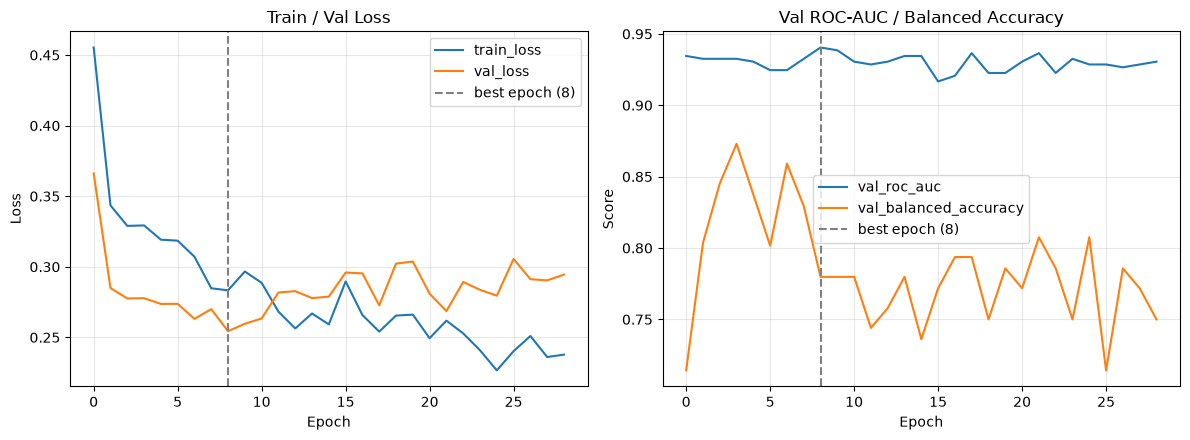

In [7]:
print("=== SECTION 6: Training Curves ===")

epochs = [h["epoch"] for h in history]
train_losses = [h["train_loss"] for h in history]
val_losses = [h["val_loss"] for h in history]
val_roc_aucs = [h["val_roc_auc"] for h in history]
val_bal_accs = [h["val_balanced_accuracy"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs, train_losses, label="train_loss")
axes[0].plot(epochs, val_losses, label="val_loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Train / Val Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, val_roc_aucs, label="val_roc_auc")
axes[1].plot(epochs, val_bal_accs, label="val_balanced_accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Val ROC-AUC / Balanced Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Section 7 — Checkpoint Reload Sanity Check

Builds a **fresh** model instance, loads the saved `state_dict`, and
re-evaluates on `val_loader`. If this doesn't match the `best_val_roc_auc`
recorded during training, something is wrong with the save/load path
(wrong epoch saved, state dict mismatch, etc.) — and that's exactly the
kind of bug we want caught here, before Phase 11 relies on this file for
the one-time final test evaluation.

In [8]:
print("=== SECTION 7: Checkpoint Reload Sanity Check ===")

reloaded_model = build_model(PRIMARY_CONFIG).to(device)
reloaded_model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))

reload_metrics = evaluate(reloaded_model, val_loader, criterion, device,
                           PRIMARY_CONFIG["graph_topology"], PRIMARY_CONFIG["image_key"])

diff = abs(reload_metrics["roc_auc"] - best_val_roc_auc)
reload_check_passed = diff < 1e-6

print(f"Recorded best_val_roc_auc during training: {best_val_roc_auc:.6f}")
print(f"Reloaded checkpoint val_roc_auc:            {reload_metrics['roc_auc']:.6f}")
print(f"Absolute difference: {diff:.2e}")
print("PASS" if reload_check_passed else "FAIL",
      "- checkpoint reload reproduces the recorded best val_roc_auc" if reload_check_passed
      else "- MISMATCH: checkpoint save/load path has a bug, investigate before Phase 11")

=== SECTION 7: Checkpoint Reload Sanity Check ===
Recorded best_val_roc_auc during training: 0.940476
Reloaded checkpoint val_roc_auc:            0.940476
Absolute difference: 0.00e+00
PASS - checkpoint reload reproduces the recorded best val_roc_auc


## Section 8 — Save Training Summary

In [9]:
print("=== SECTION 8: Save Training Summary ===")

SUMMARY_PATH = CHECKPOINT_DIR / "primary_model_summary.json"

summary = {
    "config": PRIMARY_CONFIG,
    "hyperparameters": {
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": 16,
    },
    "class_weights": {
        "weight_control": weight_control,
        "weight_dm": weight_dm,
        "pos_weight_used": "weight_dm",
    },
    "best_epoch": best_epoch,
    "best_val_roc_auc": best_val_roc_auc,
    "best_val_balanced_accuracy": history[best_epoch]["val_balanced_accuracy"],
    "total_epochs_run": total_epochs_run,
    "early_stopping_triggered": early_stopping_triggered,
    "checkpoint_path": str(CHECKPOINT_PATH),
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", SUMMARY_PATH)
print(json.dumps(summary, indent=2))

=== SECTION 8: Save Training Summary ===
Saved: c:\workstation\3RD YEAR\Diabetic_Foot\checkpoints\primary_model_summary.json
{
  "config": {
    "use_graph_branch": true,
    "use_image_branch": true,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3
  },
  "hyperparameters": {
    "max_epochs": 150,
    "patience": 20,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 16
  },
  "class_weights": {
    "weight_control": 1.8709677419354838,
    "weight_dm": 0.6823529411764706,
    "pos_weight_used": "weight_dm"
  },
  "best_epoch": 8,
  "best_val_roc_auc": 0.9404761904761905,
  "best_val_balanced_accuracy": 0.7797619047619048,
  "total_epochs_run": 29,
  "early_stopping_triggered": true,
  "checkpoint_path": "c:\\workstation\\3RD YEAR\\Diabetic_Foot\\checkpoints\\primary_model_best.pt"
}


## Section 9 — Save to `src/train.py`

Writes `build_model`, `train_one_epoch`, `evaluate`, and `train_model` out
to `src/train.py` via `inspect.getsource()` on the live functions defined
above (same pattern used for `src/model.py` in Phase 8 and
`src/mc_dropout.py` in Phase 9), so Phase 12's ablation notebook can import
this exact, already-validated training procedure instead of duplicating the
loop across configs.

In [10]:
import inspect

TRAIN_MODULE_PATH = PROJECT_ROOT / "src" / "train.py"

module_docstring = '''"""
src/train.py -- Training procedure for the Physics-Informed Dual-Branch GAT (Phase 10).

Diabetic foot thermography project. Written out programmatically by
09_training.ipynb Section 9 (via inspect.getsource on the live functions
defined in that notebook's Sections 2-4), so this file and the notebook stay
in sync.

IMPORTANT:
  - evaluate() uses PLAIN model.eval() -- it does NOT use MC-Dropout. MC-Dropout
    (src/mc_dropout.py, Phase 9) is reserved for Phase 11's final evaluation.
  - This module never touches the test split itself -- what a caller passes as
    `loader` is entirely the caller's responsibility. 09_training.ipynb only
    ever passes train_loader/val_loader.
  - pos_weight convention: labels are 1=DM, 0=Control. DM is the majority class
    in train, so its OWN (smaller, <1) inverse-frequency weight is what should
    be passed as BCEWithLogitsLoss's pos_weight -- see 09_training.ipynb
    Section 1 markdown for the full explanation.
"""

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score

from src.model import DualBranchGAT


'''

source = module_docstring
source += inspect.getsource(build_model) + "\n\n"
source += inspect.getsource(_move_batch_to_device) + "\n\n"
source += inspect.getsource(train_one_epoch) + "\n\n"
source += inspect.getsource(evaluate) + "\n\n"
source += inspect.getsource(train_model) + "\n"

TRAIN_MODULE_PATH.parent.mkdir(parents=True, exist_ok=True)
TRAIN_MODULE_PATH.write_text(source)

print("=== SECTION 9: Saved src/train.py ===")
print(f"Written to: {TRAIN_MODULE_PATH}")
print(f"File size: {TRAIN_MODULE_PATH.stat().st_size} bytes")

import importlib
import src.train as train_module
importlib.reload(train_module)
train_module_ok = all(hasattr(train_module, name) for name in
                       ["build_model", "train_one_epoch", "evaluate", "train_model"])
print("PASS" if train_module_ok else "FAIL", "- src/train.py imports cleanly and exposes all 4 functions")

=== SECTION 9: Saved src/train.py ===
Written to: c:\workstation\3RD YEAR\Diabetic_Foot\src\train.py
File size: 6530 bytes
PASS - src/train.py imports cleanly and exposes all 4 functions


## Section 10 — Final Summary

In [11]:
print("=== SECTION 10: FINAL SUMMARY ===")

issues = []

print(f"PRIMARY_CONFIG trained: {PRIMARY_CONFIG}")
print(f"Best epoch: {best_epoch} / {total_epochs_run} epochs run "
      f"(early stopping triggered: {early_stopping_triggered})")
print(f"Best val_roc_auc:            {best_val_roc_auc:.4f}")
print(f"Best val_balanced_accuracy:  {history[best_epoch]['val_balanced_accuracy']:.4f}")
print(f"Best val_f1:                 {history[best_epoch]['val_f1']:.4f}")

print(f"\nCheckpoint reload sanity check: {'PASS' if reload_check_passed else 'FAIL'}")
if not reload_check_passed:
    issues.append("Section 7: checkpoint reload did not reproduce best_val_roc_auc.")

print(f"\ncheckpoints/primary_model_best.pt saved:    {CHECKPOINT_PATH.exists()}")
print(f"checkpoints/primary_model_summary.json saved: {SUMMARY_PATH.exists()}")
print(f"src/train.py saved:                            {train_module_ok}")
if not CHECKPOINT_PATH.exists():
    issues.append("checkpoints/primary_model_best.pt not found on disk.")
if not SUMMARY_PATH.exists():
    issues.append("checkpoints/primary_model_summary.json not found on disk.")
if not train_module_ok:
    issues.append("src/train.py did not import cleanly.")

print("\ntest_loader / test split: NEVER accessed or iterated anywhere in this notebook.")

print()
if not issues:
    print("0 issues found.")
else:
    print(f"{len(issues)} issue(s) found:")
    for i in issues:
        print(" -", i)

print("\nReady to proceed to Phase 11: final one-time evaluation on the test split, "
      "using mc_dropout_predict() on this trained checkpoint.")

=== SECTION 10: FINAL SUMMARY ===
PRIMARY_CONFIG trained: {'use_graph_branch': True, 'use_image_branch': True, 'graph_topology': 'base', 'image_key': 'colormap_image', 'image_in_channels': 3}
Best epoch: 8 / 29 epochs run (early stopping triggered: True)
Best val_roc_auc:            0.9405
Best val_balanced_accuracy:  0.7798
Best val_f1:                 0.8919

Checkpoint reload sanity check: PASS

checkpoints/primary_model_best.pt saved:    True
checkpoints/primary_model_summary.json saved: True
src/train.py saved:                            True

test_loader / test split: NEVER accessed or iterated anywhere in this notebook.

0 issues found.

Ready to proceed to Phase 11: final one-time evaluation on the test split, using mc_dropout_predict() on this trained checkpoint.
